# Embedding neighborhood protocol (Boshar et al. 2024) for exerkines
Do neighborhood sequences share properties with the query sequence?

**Protocol**
1. Take a WT exerkine and build every single-mutant sequence (each position x each of the 19 other amino acids).
2. Embed every variant (mean-pooled last layer, matrix **W**).
3. For each query variant, find its **k nearest embeddings** (cosine).
4. Look up the neighbors and measure
   - **distance to mutated position**: `|pos_query - pos_neighbor|`
   - **same mutant AA**: does the neighbor carry the same substituted amino acid?
5. Compare to chance, and visualise (t-SNE colored by mutated position and mutant AA, neighbor mutant-AA heatmap).

Reading it: a small distance means the embedding space is organized by **where** the mutation is; high same-AA accuracy means it is organized by **which** residue was introduced. In the paper's figure, DNABERT2 and NTv2 had median distance 1 with same-AA accuracy near chance (position-organized), while ESM-2 organized by mutant AA.

Section A runs the protein model (ESM-2). Section B (optional) runs a nucleotide model on the **same variants**, built by editing the codon, so the two embedding spaces are directly comparable.

In [1]:
!pip -q install transformers torch scikit-learn biopython pandas matplotlib requests

In [2]:
import io, time, random, requests, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from Bio import SeqIO, Entrez
from Bio.Seq import Seq
from Bio.Data import CodonTable

Entrez.email = "you@example.com"      # <-- set your email (NCBI requirement)
GENE = "IL6"                          # any exerkine gene symbol
K = 10                                # neighborhood size (figure sketch uses 4, panels use 10)
POS_STRIDE = 1                        # 1 = every position; raise to subsample long proteins
ESM2 = "facebook/esm2_t12_35M_UR50D"  # esm2_t30_150M_UR50D matches the paper's size comparison
RUN_GLM = False                       # Section B (nucleotide model)
dev = "cuda" if torch.cuda.is_available() else "cpu"
AA = list("ACDEFGHIKLMNPQRSTVWY")

## WT sequence from NCBI, checked against UniProt

In [3]:
def ncbi_cds(gene, organism="Homo sapiens", n=5):
    term = f"{gene}[Gene Name] AND {organism}[Organism] AND srcdb_refseq_known[Properties] AND biomol_mrna[Properties]"
    ids = Entrez.read(Entrez.esearch(db="nuccore", term=term, retmax=n))["IdList"]; time.sleep(0.4)
    best = None
    for i in ids:
        rec = SeqIO.read(Entrez.efetch(db="nuccore", id=i, rettype="gb", retmode="text"), "genbank"); time.sleep(0.4)
        for f in rec.features:
            if f.type == "CDS" and f.qualifiers.get("gene", [None])[0] == gene:
                r = dict(acc=rec.id, cds=str(f.extract(rec.seq)).upper())
                if best is None or len(r["cds"]) > len(best["cds"]): best = r
    return best

def uniprot_protein(gene, taxon=9606):
    q = f"(gene_exact:{gene}) AND (organism_id:{taxon}) AND (reviewed:true)"
    r = requests.get("https://rest.uniprot.org/uniprotkb/search", params={"query": q, "format": "fasta", "size": 1}, timeout=30)
    recs = list(SeqIO.parse(io.StringIO(r.text), "fasta"))
    return str(recs[0].seq) if recs else None

wt = ncbi_cds(GENE)
wt_prot = str(Seq(wt["cds"]).translate(to_stop=True))
up = uniprot_protein(GENE)
print(GENE, wt["acc"], len(wt_prot), "aa; matches UniProt:", wt_prot == up)

IL6 NM_000600.5 212 aa; matches UniProt: True


## Single-mutant library

In [4]:
tbl = CodonTable.unambiguous_dna_by_id[1]
syn = {}
for c, a in tbl.forward_table.items(): syn.setdefault(a, []).append(c)

def codon_for(aa, wt_codon):
    # synonymous choice closest to the WT codon (fewest nucleotide changes)
    return min(syn[aa], key=lambda c: sum(x != y for x, y in zip(c, wt_codon)))

rows = []
for p in range(0, len(wt_prot), POS_STRIDE):
    for m in AA:
        if m == wt_prot[p]: continue
        codon = codon_for(m, wt["cds"][3*p:3*p+3])
        rows.append(dict(pos=p, wt_aa=wt_prot[p], mut=m,
                         prot=wt_prot[:p] + m + wt_prot[p+1:],
                         cds=wt["cds"][:3*p] + codon + wt["cds"][3*p+3:]))
df = pd.DataFrame(rows); print(len(df), "variants")

4028 variants


## A. Protein embeddings (pLM)

In [5]:
from transformers import AutoTokenizer, EsmModel
tok = AutoTokenizer.from_pretrained(ESM2); plm = EsmModel.from_pretrained(ESM2).to(dev).eval()

@torch.no_grad()
def embed_protein(seqs, bs=64):
    out = []
    for i in range(0, len(seqs), bs):
        enc = tok(seqs[i:i+bs], return_tensors="pt", padding=True).to(dev)
        h = plm(**enc).last_hidden_state
        m = enc["attention_mask"].clone(); lens = m.sum(1)
        m[:, 0] = 0; m[torch.arange(len(m)), lens - 1] = 0        # drop <cls> and <eos>
        out.append(((h * m.unsqueeze(-1)).sum(1) / m.sum(1, keepdim=True)).cpu())
    return torch.cat(out).numpy()

E_prot = embed_protein(df.prot.tolist()); E_prot.shape

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/778 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/136M [00:00<?, ?B/s]

Some weights of EsmModel were not initialized from the model checkpoint at facebook/esm2_t12_35M_UR50D and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


(4028, 480)

## Neighborhood lookup and metrics

In [6]:
def neighborhood(E, pos, mut, k=K, seed=0):
    X = E / np.linalg.norm(E, axis=1, keepdims=True)
    S = X @ X.T; np.fill_diagonal(S, -np.inf)
    nn = np.argpartition(-S, k, axis=1)[:, :k]                    # k nearest embeddings per query
    dist = np.abs(pos[nn] - pos[:, None])                         # distance to mutated position
    same = (mut[nn] == mut[:, None])                              # same mutant AA
    rng = np.random.default_rng(seed)
    rnd = rng.integers(0, len(pos), size=nn.shape)                # random-neighbor baseline
    return dict(nn=nn, dist=dist, same=same,
                dist_rand=np.abs(pos[rnd] - pos[:, None]),
                chance_same=float(np.sum((np.bincount(mut) / len(mut)) ** 2)))

def summarize(res, name):
    return dict(model=name, median_dist=float(np.median(res["dist"].mean(1))),
                median_dist_random=float(np.median(res["dist_rand"].mean(1))),
                same_aa_acc=float(res["same"].mean()), same_aa_chance=res["chance_same"])

pos = df.pos.to_numpy(); mut = df.mut.map({a: i for i, a in enumerate(AA)}).to_numpy()
res_prot = neighborhood(E_prot, pos, mut)
pd.DataFrame([summarize(res_prot, f"ESM-2 ({ESM2.split('/')[-1]})")])

,model,median_dist,median_dist_random,same_aa_acc,same_aa_chance
0,ESM-2 (esm2_t12_35M_UR50D),23.5,66.8,0.491286,0.05005


## Figures: position distance, same-AA accuracy, mutant-AA neighborhood, t-SNE

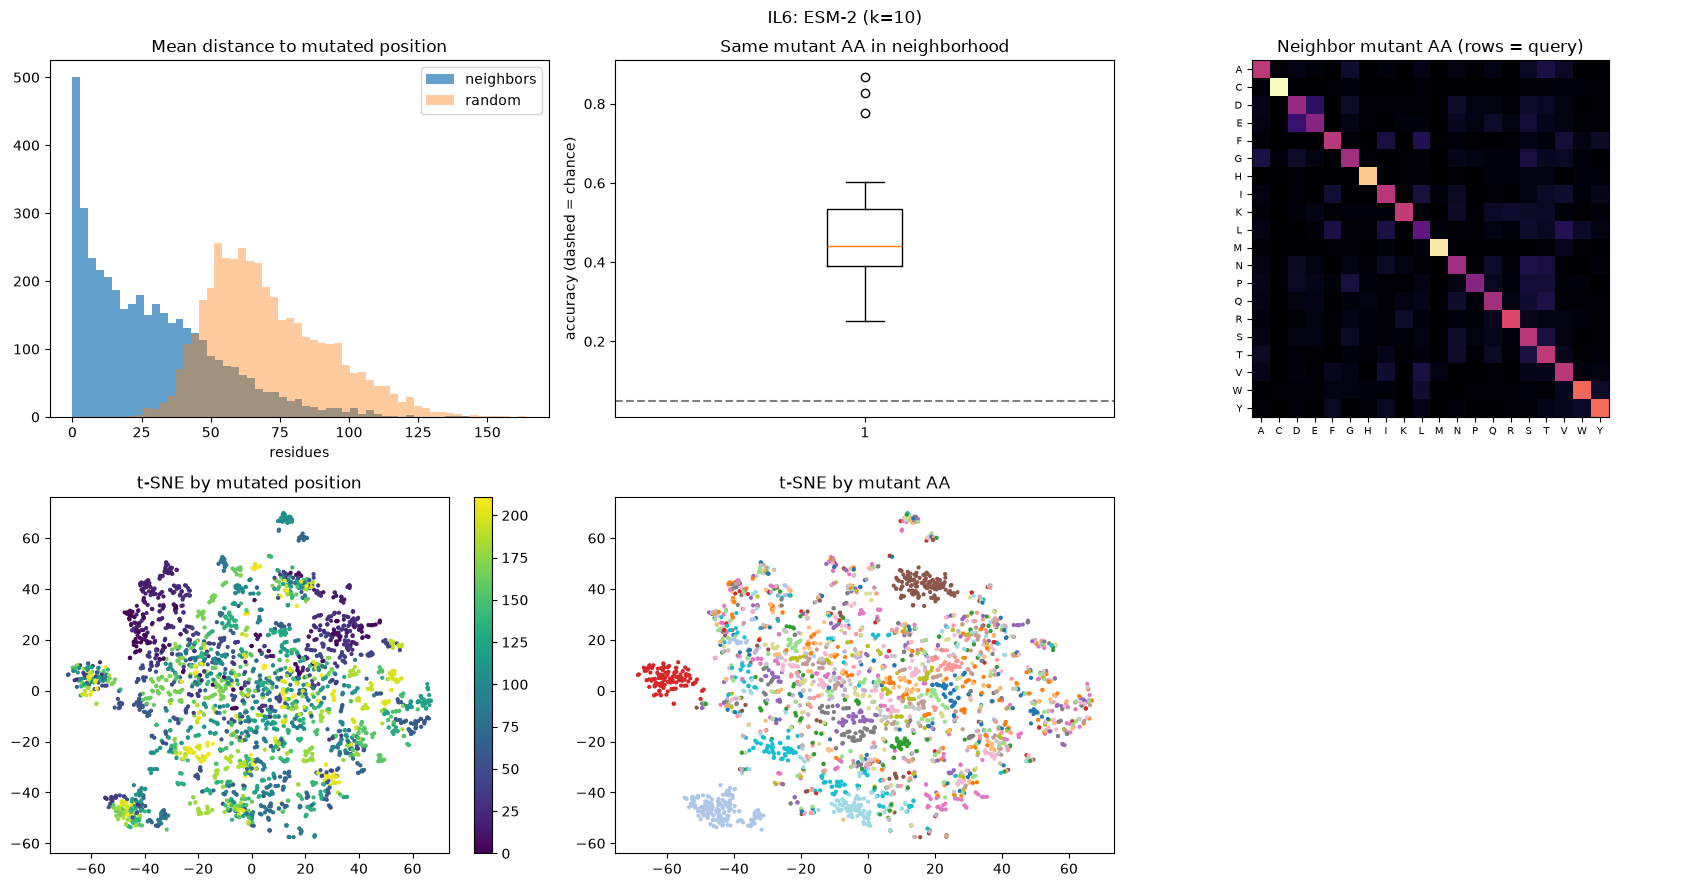

In [7]:
from sklearn.manifold import TSNE

def figure(E, res, name, n_tsne=3000):
    fig, ax = plt.subplots(2, 3, figsize=(17, 9)); fig.suptitle(f"{GENE}: {name} (k={K})")
    ax[0, 0].hist(res["dist"].mean(1), bins=50, alpha=.7, label="neighbors")
    ax[0, 0].hist(res["dist_rand"].mean(1), bins=50, alpha=.4, label="random")
    ax[0, 0].set(title="Mean distance to mutated position", xlabel="residues"); ax[0, 0].legend()
    acc = [res["same"][mut == i].mean() for i in range(20) if (mut == i).any()]
    ax[0, 1].boxplot(acc); ax[0, 1].axhline(res["chance_same"], ls="--", c="gray")
    ax[0, 1].set(title="Same mutant AA in neighborhood", ylabel="accuracy (dashed = chance)")
    M = np.zeros((20, 20))
    for q in range(len(mut)): np.add.at(M[mut[q]], mut[res["nn"][q]], 1)
    ax[0, 2].imshow(M / np.maximum(M.sum(1, keepdims=True), 1), cmap="magma")
    ax[0, 2].set(title="Neighbor mutant AA (rows = query)", xticks=range(20), yticks=range(20))
    ax[0, 2].set_xticklabels(AA, fontsize=7); ax[0, 2].set_yticklabels(AA, fontsize=7)
    idx = np.random.default_rng(0).choice(len(E), min(n_tsne, len(E)), replace=False)
    Z = TSNE(init="pca", perplexity=30, random_state=0).fit_transform(E[idx])
    s = ax[1, 0].scatter(*Z.T, c=pos[idx], s=4, cmap="viridis"); plt.colorbar(s, ax=ax[1, 0]); ax[1, 0].set_title("t-SNE by mutated position")
    ax[1, 1].scatter(*Z.T, c=mut[idx], s=4, cmap="tab20"); ax[1, 1].set_title("t-SNE by mutant AA")
    ax[1, 2].axis("off"); plt.tight_layout(); plt.show()

figure(E_prot, res_prot, "ESM-2")

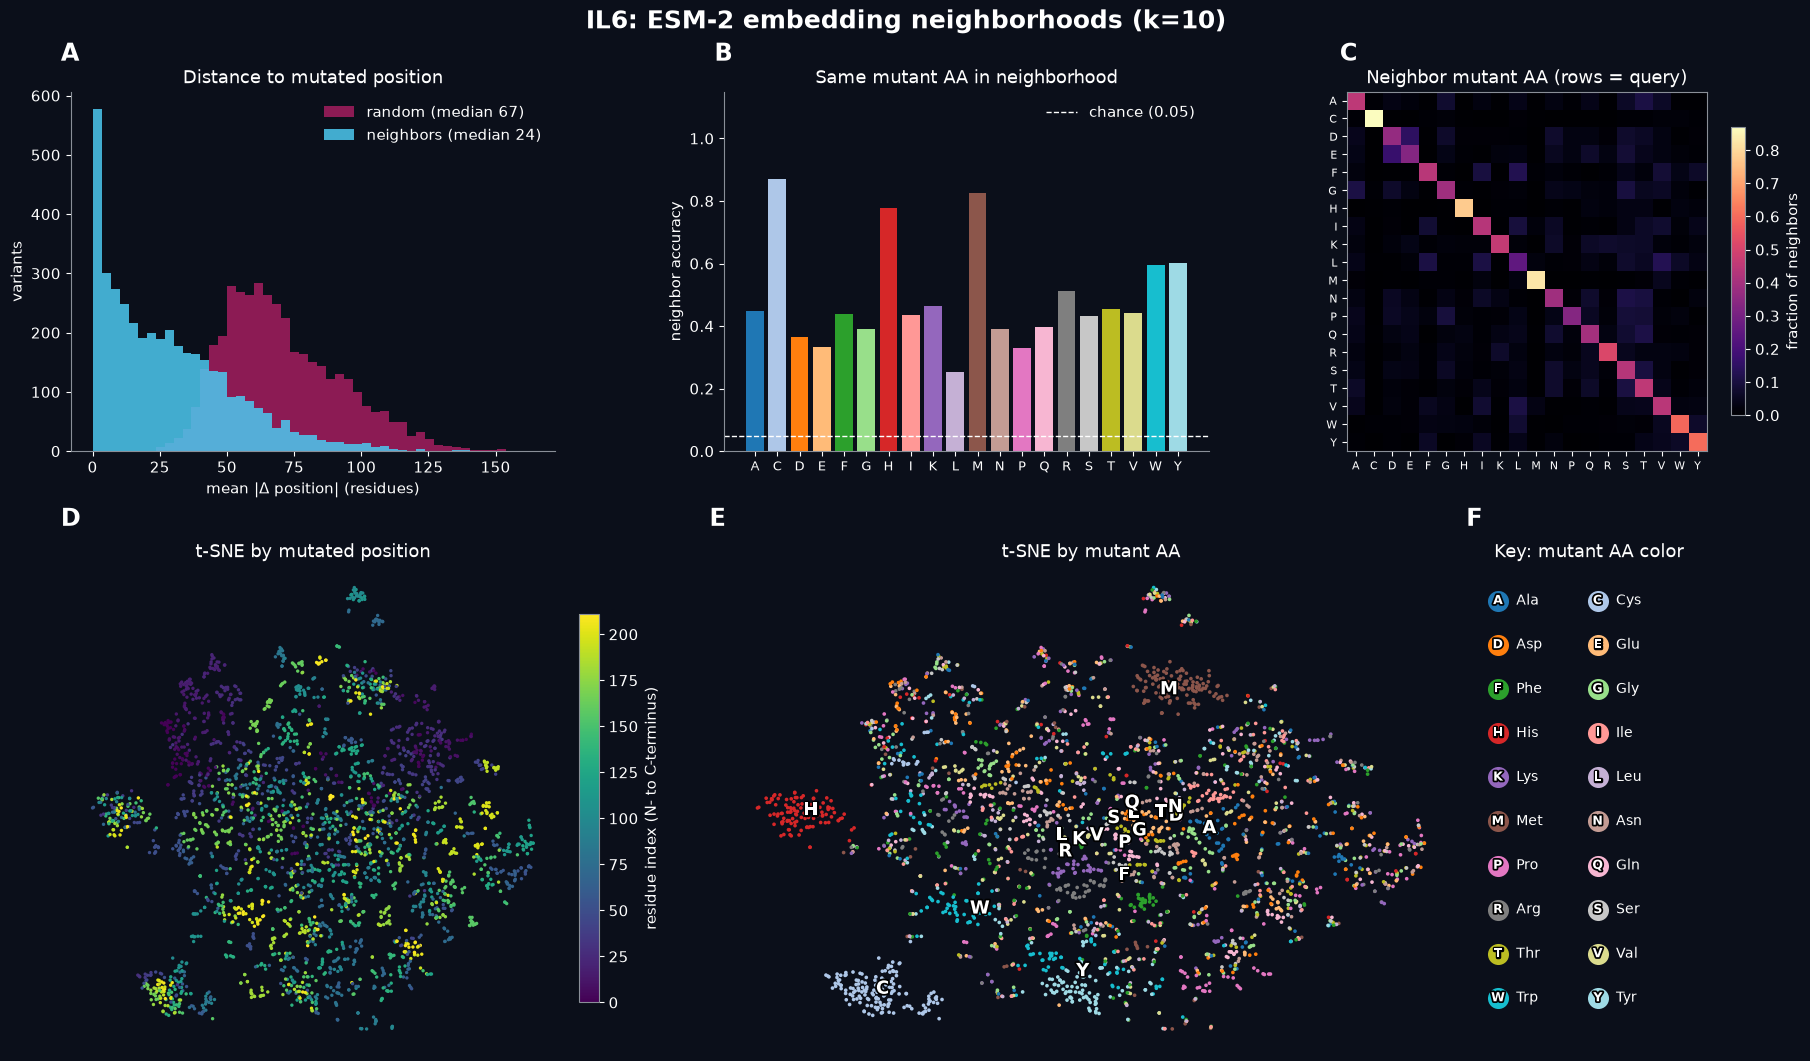

In [13]:
import numpy as np, matplotlib.pyplot as plt, matplotlib.patheffects as pe
from sklearn.manifold import TSNE

AA = list("ACDEFGHIKLMNPQRSTVWY")   # same order as the tab20 index
AA_NAMES = dict(A="Ala", C="Cys", D="Asp", E="Glu", F="Phe", G="Gly", H="His", I="Ile", K="Lys", L="Leu",
                M="Met", N="Asn", P="Pro", Q="Gln", R="Arg", S="Ser", T="Thr", V="Val", W="Trp", Y="Tyr")
AA_COLORS = {
    "A": "#1f77b4", "C": "#aec7e8", "D": "#ff7f0e", "E": "#ffbb78", "F": "#2ca02c",
    "G": "#98df8a", "H": "#d62728", "I": "#ff9896", "K": "#9467bd", "L": "#c5b0d5",
    "M": "#8c564b", "N": "#c49c94", "P": "#e377c2", "Q": "#f7b6d2", "R": "#7f7f7f",
    "S": "#c7c7c7", "T": "#bcbd22", "V": "#dbdb8d", "W": "#17becf", "Y": "#9edae5",
}

def figure_all(E, res, name, n_tsne=3000, dark=True, save=None, Z=None, idx=None):
    """One figure: A distance, B same-AA accuracy, C neighbor heatmap, D/E t-SNE, F color key.
    Pass Z, idx (e.g. Z_prot, idx_prot) to reuse an existing t-SNE; dark=False for a white background."""
    fg, bg = ("white", "#0b0f1a") if dark else ("black", "white")
    if Z is None:
        idx = np.random.default_rng(0).choice(len(E), min(n_tsne, len(E)), replace=False)
        Z = TSNE(init="pca", perplexity=30, random_state=0).fit_transform(E[idx])
    halo = [pe.withStroke(linewidth=2.5, foreground="black" if dark else "white")]
    rc = {"text.color": fg, "axes.labelcolor": fg, "axes.edgecolor": "#8a8f98", "xtick.color": fg,
          "ytick.color": fg, "figure.facecolor": bg, "axes.facecolor": bg, "savefig.facecolor": bg, "font.size": 11}
    with plt.rc_context(rc):
        fig = plt.figure(figsize=(18, 10.5), constrained_layout=True)
        gs = fig.add_gridspec(2, 6, height_ratios=[1, 1.35])
        axA, axB, axC = (fig.add_subplot(gs[0, i:i + 2]) for i in (0, 2, 4))
        axD, axE, axF = fig.add_subplot(gs[1, 0:2]), fig.add_subplot(gs[1, 2:5]), fig.add_subplot(gs[1, 5])
        fig.suptitle(f"{GENE}: {name} embedding neighborhoods (k={K})", fontsize=18, weight="bold")

        dn, dr = res["dist"].mean(1), res["dist_rand"].mean(1)                     # A
        bins = np.linspace(0, max(dn.max(), dr.max()), 50)
        axA.hist(dr, bins=bins, color="#f72585", alpha=.55, label=f"random (median {np.median(dr):.0f})")
        axA.hist(dn, bins=bins, color="#4cc9f0", alpha=.85, label=f"neighbors (median {np.median(dn):.0f})")
        axA.set(title="Distance to mutated position", xlabel="mean |Δ position| (residues)", ylabel="variants")
        axA.legend(frameon=False, labelcolor=fg)

        present = [i for i in range(20) if (mut == i).any()]                       # B
        acc = [res["same"][mut == i].mean() for i in present]
        axB.bar(range(len(present)), acc, color=[AA_COLORS[AA[i]] for i in present])
        axB.axhline(res["chance_same"], ls="--", c=fg, lw=1, label=f"chance ({res['chance_same']:.2f})")
        axB.set_xticks(range(len(present))); axB.set_xticklabels([AA[i] for i in present], fontsize=9)
        axB.set(title="Same mutant AA in neighborhood", ylabel="neighbor accuracy", ylim=(0, 1.15))
        axB.legend(frameon=False, labelcolor=fg)

        M = np.zeros((20, 20))                                                     # C
        for q in range(len(mut)): np.add.at(M[mut[q]], mut[res["nn"][q]], 1)
        im = axC.imshow(M / np.maximum(M.sum(1, keepdims=True), 1), cmap="magma")
        axC.set(title="Neighbor mutant AA (rows = query)", xticks=range(20), yticks=range(20))
        axC.set_xticklabels(AA, fontsize=8); axC.set_yticklabels(AA, fontsize=8)
        fig.colorbar(im, ax=axC, shrink=.8, label="fraction of neighbors")

        s = axD.scatter(*Z.T, c=pos[idx], s=6, cmap="viridis", linewidths=0)       # D
        axD.set(title="t-SNE by mutated position", xticks=[], yticks=[])
        fig.colorbar(s, ax=axD, shrink=.8, label="residue index (N- to C-terminus)")

        axE.scatter(*Z.T, c=[AA_COLORS[AA[m]] for m in mut[idx]], s=7, linewidths=0)   # E
        axE.set(title="t-SNE by mutant AA", xticks=[], yticks=[])
        for i, a in enumerate(AA):
            sel = mut[idx] == i
            if sel.any():
                cx, cy = np.median(Z[sel], axis=0)
                axE.text(cx, cy, a, ha="center", va="center", fontsize=13, weight="bold", color=fg, path_effects=halo)

        for i, a in enumerate(AA):                                                 # F: color key
            r, c = divmod(i, 2)
            axF.scatter(c * 1.1, -r, s=230, color=AA_COLORS[a], linewidths=0)
            axF.text(c * 1.1, -r, a, ha="center", va="center", fontsize=9, weight="bold", color=fg, path_effects=halo)
            axF.text(c * 1.1 + 0.2, -r, AA_NAMES[a], va="center", fontsize=10)
        axF.set(title="Key: mutant AA color", xlim=(-0.3, 2.3), ylim=(-10.2, 0.8)); axF.axis("off")

        for ax_, L in zip((axA, axB, axC, axD, axE, axF), "ABCDEF"):
            ax_.text(-0.02, 1.07, L, transform=ax_.transAxes, fontsize=17, weight="bold", va="bottom")
        for ax_ in (axA, axB):
            ax_.spines[["top", "right"]].set_visible(False)
        for ax_ in (axD, axE):
            for sp in ax_.spines.values(): sp.set_visible(False)
        if save: fig.savefig(save, dpi=300)
        plt.show()
    return fig

fig = figure_all(E_prot, res_prot, "ESM-2", Z=globals().get("Z_prot"), idx=globals().get("idx_prot"), save=f"{GENE}_ESM2_neighborhoods.png")

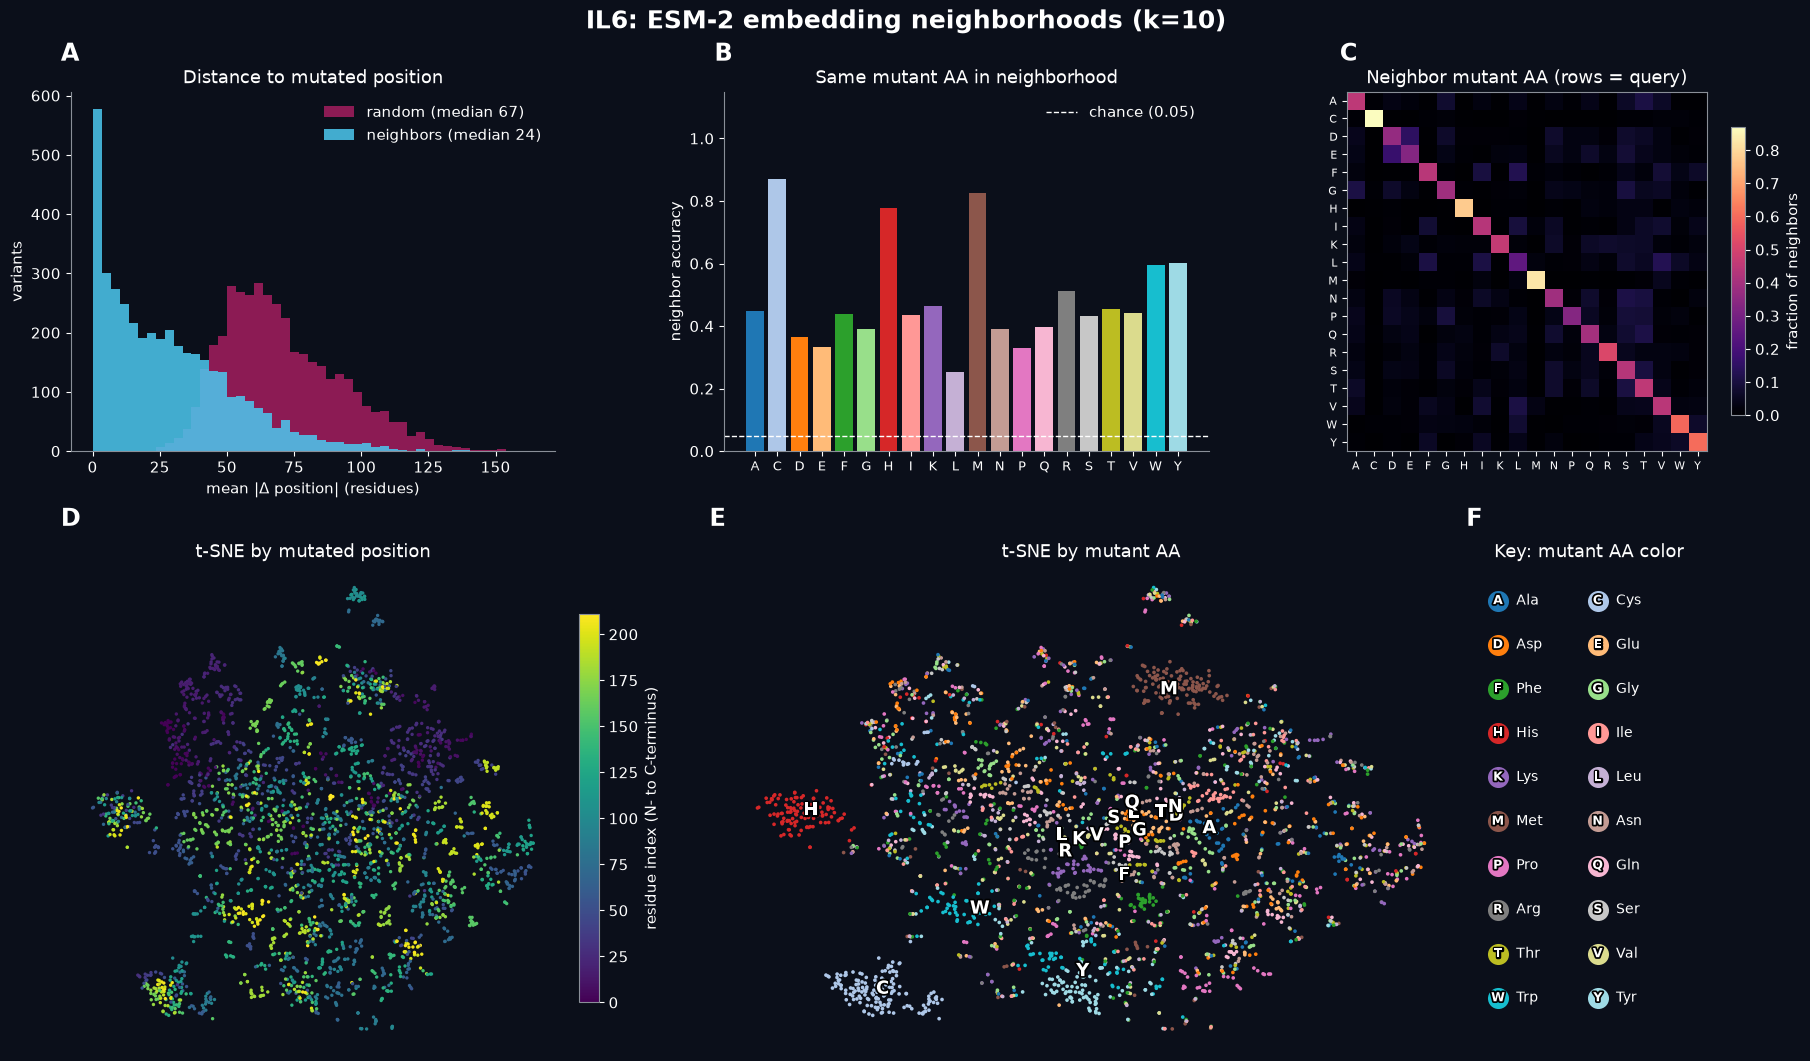

['IL6_ESM2_tsne_position.png', 'IL6_ESM2_tsne_mutant_aa.png']

In [14]:
import numpy as np, matplotlib.pyplot as plt, matplotlib.patheffects as pe
from sklearn.manifold import TSNE

AA = list("ACDEFGHIKLMNPQRSTVWY")   # same order as the tab20 index
AA_NAMES = dict(A="Ala", C="Cys", D="Asp", E="Glu", F="Phe", G="Gly", H="His", I="Ile", K="Lys", L="Leu",
                M="Met", N="Asn", P="Pro", Q="Gln", R="Arg", S="Ser", T="Thr", V="Val", W="Trp", Y="Tyr")
AA_COLORS = {
    "A": "#1f77b4", "C": "#aec7e8", "D": "#ff7f0e", "E": "#ffbb78", "F": "#2ca02c",
    "G": "#98df8a", "H": "#d62728", "I": "#ff9896", "K": "#9467bd", "L": "#c5b0d5",
    "M": "#8c564b", "N": "#c49c94", "P": "#e377c2", "Q": "#f7b6d2", "R": "#7f7f7f",
    "S": "#c7c7c7", "T": "#bcbd22", "V": "#dbdb8d", "W": "#17becf", "Y": "#9edae5",
}

def figure_all(E, res, name, n_tsne=3000, dark=True, save=None, Z=None, idx=None, transparent=False):
    """One figure: A distance, B same-AA accuracy, C neighbor heatmap, D/E t-SNE, F color key.
    Pass Z, idx (e.g. Z_prot, idx_prot) to reuse an existing t-SNE; dark=False for a white background;
    transparent=True makes the saved PNG fully transparent (text color still follows dark)."""
    fg, bg = ("white", "#0b0f1a") if dark else ("black", "white")
    if Z is None:
        idx = np.random.default_rng(0).choice(len(E), min(n_tsne, len(E)), replace=False)
        Z = TSNE(init="pca", perplexity=30, random_state=0).fit_transform(E[idx])
    if transparent: bg = "none"
    halo = [pe.withStroke(linewidth=2.5, foreground="black" if dark else "white")]
    rc = {"text.color": fg, "axes.labelcolor": fg, "axes.edgecolor": "#8a8f98", "xtick.color": fg,
          "ytick.color": fg, "figure.facecolor": bg, "axes.facecolor": bg, "savefig.facecolor": bg, "savefig.transparent": transparent, "font.size": 11}
    with plt.rc_context(rc):
        fig = plt.figure(figsize=(18, 10.5), constrained_layout=True)
        gs = fig.add_gridspec(2, 6, height_ratios=[1, 1.35])
        axA, axB, axC = (fig.add_subplot(gs[0, i:i + 2]) for i in (0, 2, 4))
        axD, axE, axF = fig.add_subplot(gs[1, 0:2]), fig.add_subplot(gs[1, 2:5]), fig.add_subplot(gs[1, 5])
        fig.suptitle(f"{GENE}: {name} embedding neighborhoods (k={K})", fontsize=18, weight="bold")

        dn, dr = res["dist"].mean(1), res["dist_rand"].mean(1)                     # A
        bins = np.linspace(0, max(dn.max(), dr.max()), 50)
        axA.hist(dr, bins=bins, color="#f72585", alpha=.55, label=f"random (median {np.median(dr):.0f})")
        axA.hist(dn, bins=bins, color="#4cc9f0", alpha=.85, label=f"neighbors (median {np.median(dn):.0f})")
        axA.set(title="Distance to mutated position", xlabel="mean |Δ position| (residues)", ylabel="variants")
        axA.legend(frameon=False, labelcolor=fg)

        present = [i for i in range(20) if (mut == i).any()]                       # B
        acc = [res["same"][mut == i].mean() for i in present]
        axB.bar(range(len(present)), acc, color=[AA_COLORS[AA[i]] for i in present])
        axB.axhline(res["chance_same"], ls="--", c=fg, lw=1, label=f"chance ({res['chance_same']:.2f})")
        axB.set_xticks(range(len(present))); axB.set_xticklabels([AA[i] for i in present], fontsize=9)
        axB.set(title="Same mutant AA in neighborhood", ylabel="neighbor accuracy", ylim=(0, 1.15))
        axB.legend(frameon=False, labelcolor=fg)

        M = np.zeros((20, 20))                                                     # C
        for q in range(len(mut)): np.add.at(M[mut[q]], mut[res["nn"][q]], 1)
        im = axC.imshow(M / np.maximum(M.sum(1, keepdims=True), 1), cmap="magma")
        axC.set(title="Neighbor mutant AA (rows = query)", xticks=range(20), yticks=range(20))
        axC.set_xticklabels(AA, fontsize=8); axC.set_yticklabels(AA, fontsize=8)
        fig.colorbar(im, ax=axC, shrink=.8, label="fraction of neighbors")

        s = axD.scatter(*Z.T, c=pos[idx], s=6, cmap="viridis", linewidths=0)       # D
        axD.set(title="t-SNE by mutated position", xticks=[], yticks=[])
        fig.colorbar(s, ax=axD, shrink=.8, label="residue index (N- to C-terminus)")

        axE.scatter(*Z.T, c=[AA_COLORS[AA[m]] for m in mut[idx]], s=7, linewidths=0)   # E
        axE.set(title="t-SNE by mutant AA", xticks=[], yticks=[])
        for i, a in enumerate(AA):
            sel = mut[idx] == i
            if sel.any():
                cx, cy = np.median(Z[sel], axis=0)
                axE.text(cx, cy, a, ha="center", va="center", fontsize=13, weight="bold", color=fg, path_effects=halo)

        for i, a in enumerate(AA):                                                 # F: color key
            r, c = divmod(i, 2)
            axF.scatter(c * 1.1, -r, s=230, color=AA_COLORS[a], linewidths=0)
            axF.text(c * 1.1, -r, a, ha="center", va="center", fontsize=9, weight="bold", color=fg, path_effects=halo)
            axF.text(c * 1.1 + 0.2, -r, AA_NAMES[a], va="center", fontsize=10)
        axF.set(title="Key: mutant AA color", xlim=(-0.3, 2.3), ylim=(-10.2, 0.8)); axF.axis("off")

        for ax_, L in zip((axA, axB, axC, axD, axE, axF), "ABCDEF"):
            ax_.text(-0.02, 1.07, L, transform=ax_.transAxes, fontsize=17, weight="bold", va="bottom")
        for ax_ in (axA, axB):
            ax_.spines[["top", "right"]].set_visible(False)
        for ax_ in (axD, axE):
            for sp in ax_.spines.values(): sp.set_visible(False)
        if save: fig.savefig(save, dpi=300)
        plt.show()
    return fig, Z, idx


def save_tsne_transparent(Z, idx, prefix, dark=True, dpi=300):
    """Save the two t-SNE plots as separate PNGs with transparent backgrounds."""
    from matplotlib.lines import Line2D
    fg = "white" if dark else "black"
    halo = [pe.withStroke(linewidth=2.5, foreground="black" if dark else "white")]
    rc = {"text.color": fg, "axes.labelcolor": fg, "xtick.color": fg, "ytick.color": fg, "font.size": 11,
          "figure.facecolor": "none", "axes.facecolor": "none", "savefig.facecolor": "none", "savefig.transparent": True}
    paths = []
    with plt.rc_context(rc):
        fig, ax = plt.subplots(figsize=(7.5, 6))                                   # colored by mutated position
        sc = ax.scatter(*Z.T, c=pos[idx], s=8, cmap="viridis", linewidths=0)
        ax.axis("off"); ax.set_title("t-SNE by mutated position", color=fg)
        fig.colorbar(sc, ax=ax, shrink=.8, label="residue index (N- to C-terminus)")
        paths.append(f"{prefix}_tsne_position.png"); fig.savefig(paths[-1], dpi=dpi); plt.close(fig)

        fig, ax = plt.subplots(figsize=(10, 6))                                    # colored by mutant AA
        ax.scatter(*Z.T, c=[AA_COLORS[AA[m]] for m in mut[idx]], s=9, linewidths=0)
        for i, a in enumerate(AA):
            sel = mut[idx] == i
            if sel.any():
                cx, cy = np.median(Z[sel], axis=0)
                ax.text(cx, cy, a, ha="center", va="center", fontsize=13, weight="bold", color=fg, path_effects=halo)
        handles = [Line2D([0], [0], marker="o", ls="", color=AA_COLORS[a], markersize=8, label=f"{a} {AA_NAMES[a]}") for a in AA]
        ax.legend(handles=handles, title="Mutant AA", bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2,
                  frameon=False, labelcolor=fg, fontsize=9, title_fontsize=10)
        ax.axis("off"); ax.set_title("t-SNE by mutant AA", color=fg)
        paths.append(f"{prefix}_tsne_mutant_aa.png"); fig.savefig(paths[-1], dpi=dpi, bbox_inches="tight"); plt.close(fig)
    return paths

fig, Z_prot, idx_prot = figure_all(E_prot, res_prot, "ESM-2", Z=globals().get("Z_prot"), idx=globals().get("idx_prot"),
                                  save=f"{GENE}_ESM2_neighborhoods.png")
save_tsne_transparent(Z_prot, idx_prot, f"{GENE}_ESM2")   # transparent PNGs of the two t-SNE plots

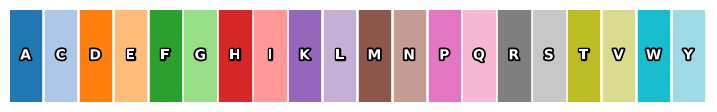

In [11]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

AA = list("ACDEFGHIKLMNPQRSTVWY")   # same order as the tab20 index used in the figure
AA_COLORS = {
    "A": "#1f77b4", "C": "#aec7e8", "D": "#ff7f0e", "E": "#ffbb78", "F": "#2ca02c",
    "G": "#98df8a", "H": "#d62728", "I": "#ff9896", "K": "#9467bd", "L": "#c5b0d5",
    "M": "#8c564b", "N": "#c49c94", "P": "#e377c2", "Q": "#f7b6d2", "R": "#7f7f7f",
    "S": "#c7c7c7", "T": "#bcbd22", "V": "#dbdb8d", "W": "#17becf", "Y": "#9edae5",
}

# swatch preview: white text with a dark outline
outline = [pe.withStroke(linewidth=2.5, foreground="black")]
fig, ax = plt.subplots(figsize=(9, 1.2))
for i, a in enumerate(AA):
    ax.add_patch(plt.Rectangle((i, 0), 0.9, 1, color=AA_COLORS[a]))
    ax.text(i + 0.45, 0.5, a, ha="center", va="center", weight="bold",
            color="white", path_effects=outline)
ax.set_xlim(0, 20); ax.set_ylim(0, 1); ax.axis("off"); plt.show()

# use in a scatter, where `mut` holds integer AA indices and `idx` the plotted subset:
# plt.scatter(*Z.T, c=[AA_COLORS[AA[m]] for m in mut[idx]], s=4)

## B. Nucleotide embeddings (gLM) on the same variants
Same variants, but the model sees the edited CDS. Enable with `RUN_GLM = True`.

In [8]:
if RUN_GLM:
    from transformers import AutoModelForMaskedLM
    NT = "InstaDeepAI/nucleotide-transformer-v2-50m-multi-species"
    ntok = AutoTokenizer.from_pretrained(NT, trust_remote_code=True)
    glm = AutoModelForMaskedLM.from_pretrained(NT, trust_remote_code=True).to(dev).eval()

    @torch.no_grad()
    def embed_dna(seqs, bs=16):
        out = []
        for i in range(0, len(seqs), bs):
            enc = ntok(seqs[i:i+bs], return_tensors="pt", padding=True).to(dev)
            h = glm(**enc, output_hidden_states=True).hidden_states[-1]
            m = enc["attention_mask"].unsqueeze(-1)
            out.append(((h * m).sum(1) / m.sum(1)).cpu())
        return torch.cat(out).numpy()

    E_dna = embed_dna(df.cds.tolist())
    res_dna = neighborhood(E_dna, pos, mut)
    display(pd.DataFrame([summarize(res_prot, "ESM-2"), summarize(res_dna, "NT-v2 50M")]))
    figure(E_dna, res_dna, "NT-v2 50M")

## How to read the answer
| Observation | Interpretation |
|---|---|
| `median_dist` far below `median_dist_random`, `same_aa_acc` near chance | embeddings organized by **mutated position**; neighbors share the *site*, not the residue |
| `median_dist` near random, `same_aa_acc` well above chance | embeddings organized by **mutant amino acid**; neighbors share the *substitution*, across the whole protein |
| both near baseline | embedding is insensitive to single substitutions (try a larger model, or a different pooling) |

Caveats: mean pooling dilutes a single-residue change, so try per-residue or mutated-position pooling as a sensitivity check. For the nucleotide model, the codon edit changes up to three bases, so position effects are partly nucleotide-level. With one WT, "position" and "protein context" are confounded; repeat across several exerkines.